<a href="https://colab.research.google.com/github/adamdeeplocal/colab-notebooks/blob/main/Sketcher.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Get the Class names

This file contains a subset of the quick draw classes. I choose around 100 classes from the dataset.

Read the classes names

In [22]:
classes = [
  "frying_pan",
  "saw",
  "pants",
  "traffic_light",
  "axe",
  "cup",
  "screwdriver",
  "ice_cream",
  "face",
  "rainbow",
  "grapes",
  "table",
  "bicycle",
  "ceiling_fan",
  "bread",
  "sword",
  "butterfly",
  "tree",
  "scissors",
  "snake",
  "camera",
  "cookie",
  "chair",
  "coffee_cup",
  "car",
  "lollipop",
  "ladder",
  "bird",
  "moon",
  "anvil",
  "pizza",
  "door",
  "spoon",
  "tent",
  "diving_board",
  "bench",
  "spider",
  "hot_dog",
  "moustache",
  "triangle",
  "clock",
  "square",
  "beard",
  "smiley_face",
  "hammer",
  "apple",
  "wheel",
  "basketball",
  "bed",
  "airplane",
  "envelope",
  "broom",
  "helmet",
  "cat",
  "pencil",
  "key",
  "cell_phone",
  "shovel",
  "baseball",
  "donut",
  "sock",
  "flower",
  "fan",
  "circle",
  "power_outlet",
  "drums",
  "candle",
  "star",
  "tooth",
  "t-shirt",
  "eye",
  "line",
  "baseball_bat",
  "stop_sign",
  "bridge",
  "knife",
  "rifle",
  "mushroom",
  "hat",
  "shorts",
  "eyeglasses",
  "suitcase",
  "mountain",
  "book",
  "dumbbell",
  "umbrella",
  "cloud",
  "tennis_racquet",
  "wristwatch",
  "alarm_clock",
  "laptop",
  "paper_clip",
  "light_bulb",
  "lightning",
  "syringe",
  "headphones",
  "sun",
  "radio",
  "microphone",
  "pillow"
]

# Download the Dataset

Loop over the classes and download the corresponding data

In [2]:
!mkdir data

In [3]:
import urllib.request
def download():

  base = 'https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/'
  for c in classes:
    cls_url = c.replace('_', '%20')
    path = base+cls_url+'.npy'
    print(path)
    urllib.request.urlretrieve(path, 'data/'+c+'.npy')

In [4]:
download()

https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/frying%20pan.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/saw.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/pants.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/traffic%20light.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/axe.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/cup.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/screwdriver.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/ice%20cream.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/face.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/rainbow.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/grapes.npy
https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/table.npy
https://storage.googleapis.com/quickdraw_dataset/fu

# Imports

In [6]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 17.7 MB/s  0:00:16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 93.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]


In [8]:
import os
import glob
import numpy as np
from tensorflow.keras import layers
from tensorflow import keras
import tensorflow as tf

# Load the Data

Each class contains different number samples of arrays stored as .npy format. Since we have some memory limitations we only load 5000 images per class.  

In [23]:
def load_data(root, vfold_ratio=0.2, max_items_per_class=10000):
    # initialize variables
    x = np.empty([0, 784])
    y = np.empty([0])
    class_names = []

    # load each data file in the exact order specified in 'classes'
    for idx, class_name in enumerate(classes):
        file_path = os.path.join(root, f"{class_name}.npy")
        if os.path.exists(file_path):
            data = np.load(file_path)
            data = data[0: max_items_per_class, :]
            labels = np.full(data.shape[0], idx)

            x = np.concatenate((x, data), axis=0)
            y = np.append(y, labels)
            class_names.append(class_name)
        else:
            print(f"Warning: {file_path} not found.")

    data = None
    labels = None

    # randomize the dataset
    permutation = np.random.permutation(y.shape[0])
    x = x[permutation, :]
    y = y[permutation]

    # separate into training and testing
    vfold_size = int(x.shape[0]/100*(vfold_ratio*100))

    x_test = x[0:vfold_size, :]
    y_test = y[0:vfold_size]

    x_train = x[vfold_size:x.shape[0], :]
    y_train = y[vfold_size:y.shape[0]]
    return x_train, y_train, x_test, y_test, class_names

In [24]:
x_train, y_train, x_test, y_test, class_names = load_data('data')
num_classes = len(class_names)
image_size = 28

In [25]:
print(len(x_train))

800000


Show some random data

spider


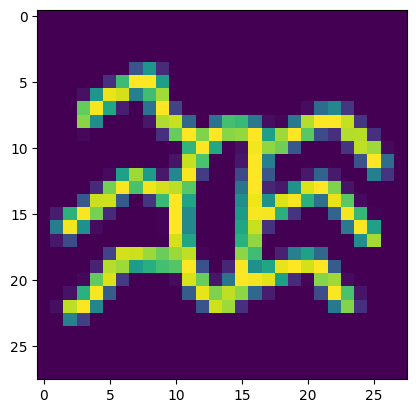

In [26]:
import matplotlib.pyplot as plt
from random import randint
%matplotlib inline
idx = randint(0, len(x_train))
plt.imshow(x_train[idx].reshape(28,28))
print(class_names[int(y_train[idx].item())])

# Preprocess the Data

In [27]:
# Reshape and normalize
x_train = x_train.reshape(x_train.shape[0], image_size, image_size, 1).astype('float32')
x_test = x_test.reshape(x_test.shape[0], image_size, image_size, 1).astype('float32')

x_train /= 255.0
x_test /= 255.0

# Convert class vectors to class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

# The Model

In [28]:
# Define model
model = keras.Sequential()
model.add(layers.Convolution2D(16, (3, 3),
                        padding='same',
                        input_shape=x_train.shape[1:], activation='relu'))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Convolution2D(32, (3, 3), padding='same', activation= 'relu'))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Convolution2D(64, (3, 3), padding='same', activation= 'relu'))
model.add(layers.MaxPooling2D(pool_size =(2,2)))
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='tanh'))
model.add(layers.Dense(100, activation='softmax'))
# Train model
adam = tf.keras.optimizers.Adam()
model.compile(loss='categorical_crossentropy',
              optimizer=adam,
              metrics=['top_k_categorical_accuracy'])
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,052 (429.89 KB)

 Trainable params: 110,052 (429.89 KB)

 Non-trainable params: 0 (0.00 B)

None


# Training

In [29]:
model.fit(x = x_train, y = y_train, validation_split=0.1, batch_size = 256, verbose=2, epochs=5)

Epoch 1/5
2813/2813 - 163s - 58ms/step - loss: 1.4639 - top_k_categorical_accuracy: 0.8559 - val_loss: 1.0615 - val_top_k_categorical_accuracy: 0.9125
Epoch 2/5
2813/2813 - 161s - 57ms/step - loss: 0.9773 - top_k_categorical_accuracy: 0.9206 - val_loss: 0.9178 - val_top_k_categorical_accuracy: 0.9266
Epoch 3/5
2813/2813 - 162s - 58ms/step - loss: 0.8701 - top_k_categorical_accuracy: 0.9312 - val_loss: 0.8593 - val_top_k_categorical_accuracy: 0.9317
Epoch 4/5
2813/2813 - 162s - 58ms/step - loss: 0.8135 - top_k_categorical_accuracy: 0.9367 - val_loss: 0.8273 - val_top_k_categorical_accuracy: 0.9361
Epoch 5/5
2813/2813 - 162s - 57ms/step - loss: 0.7768 - top_k_categorical_accuracy: 0.9401 - val_loss: 0.8037 - val_top_k_categorical_accuracy: 0.9374


# Testing

In [30]:
score = model.evaluate(x_test, y_test, verbose=0)
print('Test accuracy: {:0.2f}%'.format(score[1] * 100))

Test accuracy: 93.67%


# Inference

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
['tennis_racquet', 'spoon', 'lollipop', 'microphone', 'screwdriver']


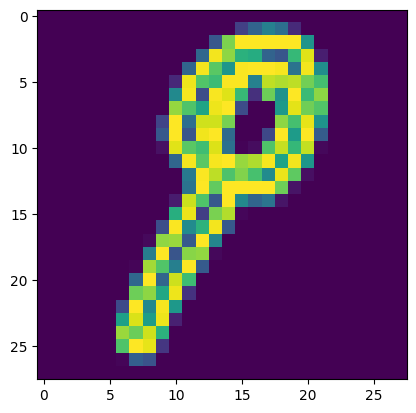

In [31]:
import matplotlib.pyplot as plt
from random import randint
%matplotlib inline
idx = randint(0, len(x_test))
img = x_test[idx]
plt.imshow(img.squeeze())
pred = model.predict(np.expand_dims(img, axis=0))[0]
ind = (-pred).argsort()[:5]
latex = [class_names[x] for x in ind]
print(latex)

# Store the classes

In [32]:
with open('class_names.txt', 'w') as file_handler:
    for item in class_names:
        file_handler.write("{}\n".format(item))

# Save model

In [33]:
model.save('quickdraw_model_10k.keras')

# Download

In [34]:
from google.colab import files
files.download('quickdraw_model_10k.keras')
# files.download('class_names.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>